# Dream in Orbit — comprendre les données

**Objectif de cette étape :** savoir ce que contient chaque fichier, repérer les trous et observer les circuits.
Lis les cellules dans l'ordre, puis exécute-les de haut en bas. Les explications font partie du notebook.

Le sujet demande ensuite de prédire **33 circuits**, heure par heure, avec seulement **7 jours de consommation réelle** au départ.
`annee1` servira à apprendre ; `annee2` servira à mesurer la capacité à prédire le futur. Aucun découpage aléatoire.

Ici, nous ne créons ni jeu d'entraînement horaire, ni modèle, ni score. Les regroupements servent uniquement aux diagnostics et aux graphiques.
Les CSV sont lus sans modification. Une seule grosse table de consommation reste en mémoire à la fois.

**Vocabulaire :** une ligne = une observation ; une colonne = une variable ; une cible = une valeur à prédire.
La cible est le courant décrit dans `docs/sujet.md`. Le nom `power.csv` ne prouve pas une mesure en watts.
L'unité et la fonction physique exacte de chaque circuit restent à confirmer avec le kit.

## Structure minimale, construite au moment utile

| Élément | Rôle | Quand ? |
|---|---|---|
| `data/annee1/`, `data/annee2/` | Conserver les six CSV bruts de chaque période | Déjà présents |
| `docs/exploration/exploration.ipynb` | Expliquer les données, contrôler leur qualité, montrer les observations | Maintenant |
| `requirements.txt` | Fixer les versions des bibliothèques utilisées ici | Maintenant |
| `dio/prepare.py` | Construire les variables horaires des actions et du contexte | Étape suivante |
| `make_validation.py` | Fournir les 7 jours initiaux, les heures demandées et la vérité horaire | Réutiliser le script présent |
| `baselines/`, puis `predict.py` | Première baseline : répéter une moyenne par circuit calculée sur `annee1` ; ensuite le world model | Plus tard |
| `evaluate.py` | Mesurer la RMSE avec le script présent | Après la baseline |

Pour préparer les données plus tard : compter les commandes par heure, mesurer le temps passé dans chaque mode,
résumer les angles solaires et rattacher le contexte journalier. Les intervalles qui traversent une heure devront être partagés.
Les chevauchements du planning doivent être compris avant de calculer des durées.

La cible horaire sera la **moyenne des mesures de chaque circuit dans l'heure**, comme dans `make_validation.py`.
Une heure sans mesure n'est pas une consommation nulle. Le futur code devra reproduire cette convention.
Le script commence les prédictions à l'heure entière qui suit la fin des 7 jours initiaux.

La RMSE est la racine de la moyenne des erreurs au carré. Elle pénalise davantage les grandes erreurs.
La baseline constante donnera un point de comparaison ; le modèle final devra être neuronal selon le sujet.

## 1. Outils et emplacement des données

`pandas` manipule les tableaux, `numpy` aide aux contrôles numériques, `matplotlib` trace les courbes.
`Path` représente un chemin. `assert` arrête le notebook si une condition indispensable est fausse.

Ouvre ce notebook avec un noyau Python disposant des dépendances : `python -m pip install -r requirements.txt`.
Le dossier de travail doit être `docs/exploration/`, là où se trouve ce notebook.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path('../../data')
PERIODES = ['annee1', 'annee2']
FICHIERS = ['power', 'dmop', 'ftl', 'saaf', 'evtf', 'ltdata']
assert Path('../sujet.md').is_file(), 'Ouvrir le notebook depuis docs/exploration/.'
pd.set_option('display.max_columns', 12)
print(f'Python {sys.version.split()[0]} ; pandas {pd.__version__} ; numpy {np.__version__} ; matplotlib {matplotlib.__version__}')

Python 3.13.9 ; pandas 2.3.3 ; numpy 2.3.5 ; matplotlib 3.10.7


## 2. Inventaire et lecture d'une ligne

| Fichier | Ce qu'une ligne représente | Temps |
|---|---|---|
| `power` | Une mesure des 33 courants : les cibles | `ut_ms` |
| `dmop` | Une commande, identifiée par un code de sous-système | `ut_ms` |
| `ftl` | Un intervalle de mode de pointage et son indicateur de communication | `utb_ms` à `ute_ms` |
| `saaf` | Les angles du Soleil par rapport au satellite | `ut_ms` |
| `evtf` | Un événement décrit par un texte | `ut_ms` |
| `ltdata` | Le contexte journalier : distances, éclipses, etc. | `ut_ms` |

Un CSV est un tableau enregistré dans un fichier texte. `read_csv(..., nrows=2)` en lit ici seulement deux lignes.
Ce petit aperçu sert à comprendre le format. Les contrôles suivants liront les fichiers **entiers**.

In [2]:
inventaire = []
for periode in PERIODES:
    for nom in FICHIERS:
        chemin = DATA / periode / f'{nom}.csv'
        assert chemin.is_file(), f'Fichier absent : {chemin}'
        inventaire.append({'periode': periode, 'fichier': nom, 'taille_Mo': chemin.stat().st_size / 1_000_000})
display(pd.DataFrame(inventaire).round(2))

for nom in FICHIERS:
    print(f'annee1/{nom}.csv — aperçu')
    display(pd.read_csv(DATA / 'annee1' / f'{nom}.csv', nrows=2))

,periode,fichier,taille_Mo
0,annee1,power,617.81
1,annee1,dmop,4.85
2,annee1,ftl,0.87
3,annee1,saaf,46.22
4,annee1,evtf,3.16
5,annee1,ltdata,0.07
6,annee2,power,591.71
7,annee2,dmop,3.74
8,annee2,ftl,0.89
9,annee2,saaf,47.63


annee1/power.csv — aperçu


,ut_ms,NPWD2372,NPWD2401,NPWD2402,NPWD2451,NPWD2471,...,NPWD2851,NPWD2852,NPWD2871,NPWD2872,NPWD2881,NPWD2882
0,1219363209542,0.001821,0.001474,0.172173,0.005015,0.000714,...,0.004982,0.000501,0.000399,0.000714,0.006457,0.003227
1,1219363241537,0.002185,0.001769,0.177440,0.006019,0.000714,...,0.004982,0.000501,0.000499,0.000857,0.007748,0.003227


annee1/dmop.csv — aperçu


,ut_ms,subsystem
0,1219363211000,AXXX301A
1,1219364909000,AAAAF20C1


annee1/ftl.csv — aperçu


... (3 outputs left out)

annee1/evtf.csv — aperçu


,ut_ms,description
0,1219364253000,MLG_LOS_05_/_RTLT_02373
1,1219364356000,NNO_AOS_00_/_RTLT_02373


annee1/ltdata.csv — aperçu


,ut_ms,sunmars_km,earthmars_km,sunmarsearthangle_deg,solarconstantmars,eclipseduration_min,occultationduration_min
0,1219363200000,2.419389e+08,3.557560e+08,19.565076,522.263999,4.166667,27.400000
1,1219449600000,2.418002e+08,3.563037e+08,19.390075,522.863537,1.783333,26.933333


Les horodatages sont des entiers en **millisecondes depuis le 1er janvier 1970**, en UTC.
`unit='ms'` indique l'unité à pandas ; `utc=True` évite de confondre UTC et l'heure locale.
Dans `ftl`, une ligne décrit une durée, pas un instant isolé.

In [3]:
exemple = pd.read_csv(DATA / 'annee1' / 'power.csv', nrows=1)
instant_ms = int(exemple.loc[0, 'ut_ms'])
print('Entier brut :', instant_ms)
print('Date UTC :', pd.to_datetime(instant_ms, unit='ms', utc=True))
H = 3_600_000  # Une heure en millisecondes, comme dans make_validation.py.
debut_heure_ms = (instant_ms // H) * H
print("Début de l'heure :", pd.to_datetime(debut_heure_ms, unit='ms', utc=True))

Entier brut : 1219363209542
Date UTC : 2008-08-22 00:00:09.542000+00:00
Début de l'heure : 2008-08-22 00:00:00+00:00


## 3. Contrôler les cinq fichiers d'actions et de contexte

Pour chaque fichier complet, on compte les lignes, les cellules manquantes et les doublons exacts.
On vérifie les colonnes et l'ordre chronologique. `diff()` mesure le temps entre deux lignes consécutives.
La médiane décrit une cadence typique ; le maximum signale un grand intervalle sans nouvelle ligne.

Des événements distincts peuvent partager le même instant : un doublon d'horodatage n'est pas forcément une erreur.
Une longue pause entre deux commandes ne prouve pas non plus une panne de télémétrie.

In [4]:
COLONNES = {
    'dmop': ['ut_ms', 'subsystem'],
    'ftl': ['utb_ms', 'ute_ms', 'type', 'flagcomms'],
    'saaf': ['ut_ms', 'sa', 'sx', 'sy', 'sz'],
    'evtf': ['ut_ms', 'description'],
    'ltdata': ['ut_ms', 'sunmars_km', 'earthmars_km', 'sunmarsearthangle_deg',
               'solarconstantmars', 'eclipseduration_min', 'occultationduration_min'],
}
bilans_contexte = []
contextes = {}  # Garder les petits tableaux utiles aux exemples et aux graphiques.
plages_angles = {}
for periode in PERIODES:
    for nom, colonnes in COLONNES.items():
        table = pd.read_csv(DATA / periode / f'{nom}.csv')
        assert table.columns.tolist() == colonnes, f'Schéma inattendu : {periode}/{nom}'
        temps = table['utb_ms' if nom == 'ftl' else 'ut_ms']
        assert temps.notna().all() and pd.api.types.is_integer_dtype(temps)
        pas = temps.diff().dropna() / 1000
        numeriques = table.select_dtypes(include='number').columns
        bilans_contexte.append({
            'periode': periode, 'fichier': nom, 'lignes': len(table),
            'debut_UTC': pd.to_datetime(temps.min(), unit='ms', utc=True),
            'fin_UTC': pd.to_datetime(temps.max(), unit='ms', utc=True),
            'cellules_NaN': int(table.isna().sum().sum()),
            'cellules_infinies': sum(int(np.isinf(table[c]).sum()) for c in numeriques),
            'doublons_ligne': int(table.duplicated().sum()),
            'instants_repetes': int(temps.duplicated().sum()),
            'temps_trie': temps.is_monotonic_increasing,
            'pas_median_s': pas.median(), 'pas_max_s': pas.max(),
        })
        if nom == 'saaf':
            plages_angles[periode] = table[['sa', 'sx', 'sy', 'sz']].agg(['min', 'max'])
        else:
            contextes[periode, nom] = table
del table
bilan_contexte = pd.DataFrame(bilans_contexte)
display(bilan_contexte[['periode', 'fichier', 'lignes', 'debut_UTC', 'fin_UTC', 'pas_median_s', 'pas_max_s']])
display(bilan_contexte[['periode', 'fichier', 'cellules_NaN', 'cellules_infinies',
                       'doublons_ligne', 'instants_repetes', 'temps_trie']])

,periode,fichier,lignes,debut_UTC,fin_UTC,pas_median_s,pas_max_s
0,annee1,dmop,187126,2008-08-22 00:00:11+00:00,2010-07-09 23:57:27+00:00,13.0,1291141.0
1,annee1,ftl,19571,2008-08-22 00:00:13+00:00,2010-07-09 23:34:20+00:00,1800.0,80824.0
2,annee1,saaf,1261290,2008-08-22 00:00:13+00:00,2010-07-09 23:59:50+00:00,60.0,60.0
3,annee1,evtf,76776,2008-08-22 00:17:33+00:00,2010-07-09 23:26:01+00:00,345.0,9667.0
4,annee1,ltdata,687,2008-08-22 00:00:00+00:00,2010-07-09 00:00:00+00:00,86400.0,86400.0
5,annee2,dmop,143802,2010-07-10 00:56:03+00:00,2012-05-14 10:39:00+00:00,14.0,3021771.0
6,annee2,ftl,20051,2010-07-10 00:52:35+00:00,2012-05-26 23:59:22+00:00,1390.5,120498.0
7,annee2,saaf,1305759,2010-07-10 00:00:39+00:00,2012-05-26 23:59:59+00:00,40.0,9420.0
8,annee2,evtf,75208,2010-07-10 00:14:36+00:00,2012-05-26 23:42:05+00:00,348.0,9678.0
9,annee2,ltdata,687,2010-07-10 00:00:00+00:00,2012-05-26 00:00:00+00:00,86400.0,86400.0


,periode,fichier,cellules_NaN,cellules_infinies,doublons_ligne,instants_repetes,temps_trie
0,annee1,dmop,0,0,0,0,True
1,annee1,ftl,0,0,0,0,True
2,annee1,saaf,0,0,0,0,True
3,annee1,evtf,0,0,0,68,True
4,annee1,ltdata,0,0,0,0,True
5,annee2,dmop,0,0,0,0,True
6,annee2,ftl,0,0,0,0,True
7,annee2,saaf,0,0,0,0,True
8,annee2,evtf,0,0,0,97,True
9,annee2,ltdata,0,0,0,0,True


### Le planning mérite un contrôle particulier

`ute_ms - utb_ms` donne la durée d'un intervalle. Une durée négative ou nulle serait suspecte.
Pour détecter un chevauchement, on compare chaque début à la fin maximale des intervalles précédents.
`cummax().shift()` calcule cette fin maximale sans inclure l'intervalle courant.
On trie une copie pour ce diagnostic ; le CSV reste intact.

Le compteur indique les intervalles qui croisent un intervalle précédent, pas un nombre de conflits physiques.
Il faudra comprendre ces chevauchements avant d'additionner des durées de modes par heure.

In [5]:
bilans_planning = []
for periode in PERIODES:
    planning = contextes[periode, 'ftl'].sort_values('utb_ms')
    durees = (planning['ute_ms'] - planning['utb_ms']) / 60_000
    fin_precedente = planning['ute_ms'].cummax().shift()
    bilans_planning.append({
        'periode': periode, 'modes_distincts': planning['type'].nunique(),
        'duree_mediane_min': durees.median(),
        'durees_non_positives': int(durees.le(0).sum()),
        'intervalles_avec_chevauchement': int(planning['utb_ms'].lt(fin_precedente).sum()),
    })
    print(periode, '— modes les plus fréquents (nombre de lignes, pas durée)')
    display(planning['type'].value_counts().head(5).to_frame('intervalles'))
display(pd.DataFrame(bilans_planning))

annee1 — modes les plus fréquents (nombre de lignes, pas durée)


,intervalles
type,
SLEW,7268
EARTH,6700
INERTIAL,1811
NADIR,929
WARMUP,722


annee2 — modes les plus fréquents (nombre de lignes, pas durée)


,intervalles
type,
SLEW,7739
EARTH,7108
INERTIAL,1987
D4PNPO,941
NADIR,713


,periode,modes_distincts,duree_mediane_min,durees_non_positives,intervalles_avec_chevauchement
0,annee1,14,30.000000,0,695
1,annee2,15,23.483333,0,150


### Des codes, pas encore des variables pour un modèle

`nunique()` compte les codes distincts. `value_counts()` compte leurs occurrences.
Beaucoup de codes de commandes rendent un encodage naïf très volumineux.
Le filtre textuel sur les éclipses sert seulement à lire quelques descriptions ; il ne reconstruit aucune durée.
On ne connaît pas encore le sens physique de tous les codes ni la convention exacte des angles.

In [6]:
for periode in PERIODES:
    commandes = contextes[periode, 'dmop']['subsystem']
    evenements = contextes[periode, 'evtf']['description']
    print(periode, '— codes de commande distincts :', commandes.nunique())
    display(commandes.value_counts().head(5).to_frame('occurrences'))
    print("Exemples de descriptions liées à l'ombre :")
    display(evenements[evenements.str.contains('UMBRA|ECLIP', case=False, na=False)].drop_duplicates().head(6))
print('Plages observées des angles :')
display(pd.concat(plages_angles, names=['periode', 'statistique']))

annee1 — codes de commande distincts : 9280


,occurrences
subsystem,
AAAAF56A1,12054
APSF28A1,10582
AVVV02A0,8572
AVVV03B0,8273
AAAAF20E1,7657


Exemples de descriptions liées à l'ombre :


14      MAR_PENUMBRA_START
15         MAR_UMBRA_START
16           MAR_UMBRA_END
18        MAR_PENUMBRA_END
3089    DEI_PENUMBRA_START
3090      DEI_PENUMBRA_END
Name: description, dtype: object

annee2 — codes de commande distincts : 7190


,occurrences
subsystem,
AAAAF56A1,7981
APSF28A1,7730
AAAAF20E1,5783
APSF38A1,4673
AAAAF20C1,3626


Exemples de descriptions liées à l'ombre :


2322    PHO_PENUMBRA_START
2323       PHO_UMBRA_START
2324         PHO_UMBRA_END
2325      PHO_PENUMBRA_END
7684    MAR_PENUMBRA_START
7686      MAR_PENUMBRA_END
Name: description, dtype: object

Plages observées des angles :


sa      sx      sy      sz
periode statistique                                
annee1  min            0.00    0.00    0.97    0.93
        max          147.37  106.04  179.43  179.94
annee2  min            0.00    0.00    1.44    0.84
        max          178.10   97.61  179.32  179.34

## 4. Explorer les 33 circuits sur les deux périodes complètes

Chaque `power.csv` est lu entièrement, puis libéré. Les petits résumés restent en mémoire.
Les moyennes et écarts types décrivent les valeurs ; ils ne constituent pas un entraînement.
Un grand écart type indique un circuit variable. Un petit écart type ne prouve pas un circuit inutile.

`floor('h')` rattache chaque mesure à son heure. `value_counts()` compte les mesures dans chaque heure observée.
`date_range()` construit toutes les heures attendues ; `reindex(..., fill_value=0)` révèle celles sans mesure.
**Le zéro remplit ici un compteur, jamais une valeur de courant.**

`groupby(...).mean()` calcule aussi des moyennes journalières pour les courbes.
Cette moyenne donne le même poids à chaque mesure, pas à chaque seconde écoulée.

In [7]:
bilans_power = []
stats_circuits = {}
comptages_horaires = {}
power_journalier = {}
circuits = pd.read_csv(DATA / 'annee1' / 'power.csv', nrows=0).columns[1:].tolist()
assert len(circuits) == 33 and all(c.startswith('NPWD') for c in circuits)

for periode in PERIODES:
    power = pd.read_csv(DATA / periode / 'power.csv')
    assert power.columns.tolist() == ['ut_ms'] + circuits, 'Circuits différents entre les périodes.'
    temps = power['ut_ms']
    assert temps.notna().all() and pd.api.types.is_integer_dtype(temps)
    dates = pd.to_datetime(temps, unit='ms', utc=True)
    comptes = dates.dt.floor('h').value_counts().sort_index()
    grille = pd.date_range(comptes.index.min(), comptes.index.max(), freq='h')
    comptes = comptes.reindex(grille, fill_value=0)
    assert int(comptes.sum()) == len(power), 'Chaque mesure doit être comptée une fois.'
    comptages_horaires[periode] = comptes
    power_journalier[periode] = power.groupby(dates.dt.floor('D'))[circuits].mean()
    statistiques = power[circuits].agg(['count', 'mean', 'std', 'min', 'max']).T
    statistiques['NaN'] = power[circuits].isna().sum()
    statistiques['negatives'] = power[circuits].lt(0).sum()
    stats_circuits[periode] = statistiques
    fin_init_ms = int(temps.min()) + 7 * 24 * H
    premiere_prediction = pd.to_datetime(((fin_init_ms // H) + 1) * H, unit='ms', utc=True)
    bilans_power.append({
        'periode': periode, 'lignes': len(power), 'circuits': len(circuits),
        'debut_UTC': dates.min(), 'fin_UTC': dates.max(),
        'jours_calendaires': len(power_journalier[periode]),
        'cellules_NaN': int(power.isna().sum().sum()),
        'cellules_infinies': sum(int(np.isinf(power[c]).sum()) for c in circuits),
        'doublons_ligne': int(power.duplicated().sum()),
        'instants_repetes': int(temps.duplicated().sum()),
        'temps_trie': temps.is_monotonic_increasing,
        'pas_median_s': temps.diff().median() / 1000,
        'trou_max_h': temps.diff().max() / H,
        'heures_total': len(comptes), 'heures_vides': int(comptes.eq(0).sum()),
        'mesures_par_heure_mediane': comptes.median(),
        'premiere_prediction_UTC': premiere_prediction,
        'heures_vides_apres_init': int(comptes.loc[premiere_prediction:].eq(0).sum()),
    })
    del power
bilan_power = pd.DataFrame(bilans_power).set_index('periode')
display(bilan_power.T)

periode,annee1,annee2
lignes,1830121,1768248
circuits,33,33
debut_UTC,2008-08-22 00:00:09.542000+00:00,2010-07-10 00:00:08.577000+00:00
fin_UTC,2010-07-09 23:59:36.556000+00:00,2012-05-26 23:59:37.753000+00:00
jours_calendaires,687,687
cellules_NaN,0,0
cellules_infinies,0,0
doublons_ligne,0,0
instants_repetes,0,0
temps_trie,True,True


### Une case vide et une heure absente sont deux problèmes différents

Un CSV peut n'avoir aucun `NaN` et présenter des heures totalement absentes.
La table suivante affiche les premières heures sans mesure et le nombre de mesures par heure.
On conserve les vrais zéros de courant ; ils ne sont pas automatiquement des erreurs.

annee1 — premières heures sans mesure :


,nombre_mesures
2009-03-15 08:00:00+00:00,0
2009-03-15 09:00:00+00:00,0
2009-03-15 14:00:00+00:00,0
2009-03-15 15:00:00+00:00,0
2009-03-15 16:00:00+00:00,0


annee2 — premières heures sans mesure :


,nombre_mesures
2011-02-20 01:00:00+00:00,0
2011-02-20 05:00:00+00:00,0
2011-02-20 06:00:00+00:00,0
2011-02-20 07:00:00+00:00,0
2011-02-20 08:00:00+00:00,0


,annee1,annee2
0.00,0.0,0.0
0.25,112.0,112.0
0.50,112.0,112.0
0.75,113.0,113.0
1.00,225.0,899.0


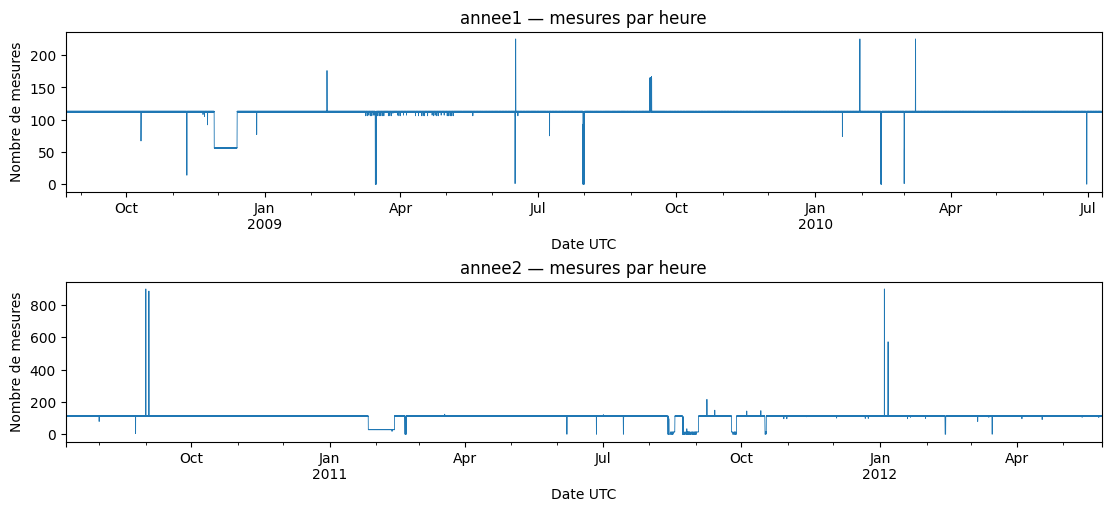

In [8]:
for periode, comptes in comptages_horaires.items():
    print(periode, '— premières heures sans mesure :')
    display(comptes[comptes.eq(0)].head(5).rename('nombre_mesures').to_frame())
display(pd.DataFrame({p: c.quantile([0, 0.25, 0.5, 0.75, 1]) for p, c in comptages_horaires.items()}))

fig, axes = plt.subplots(2, 1, figsize=(11, 5), constrained_layout=True)
for ax, (periode, comptes) in zip(axes, comptages_horaires.items()):
    comptes.plot(ax=ax, linewidth=0.6)
    ax.set(title=f'{periode} — mesures par heure', ylabel='Nombre de mesures', xlabel='Date UTC')
plt.show()

### Quels circuits varient le plus ?

On trie les circuits selon leur écart type **sur `annee1` seulement**.
Le tableau affiche les 33 circuits ; les courbes montrent les deux plus variables et le moins variable.
Chaque courbe a son échelle verticale : compare les nombres, pas seulement la forme.
Les valeurs rares ou extrêmes restent présentes ; aucun nettoyage n'est encore justifié.

,count,mean,std,min,max,NaN,negatives
NPWD2451,1830121.0,0.644853,8.402739e-01,0.004012,2.215750,0,0
NPWD2551,1830121.0,0.282007,6.061177e-01,0.000400,2.065430,0,0
NPWD2561,1830121.0,0.322844,3.654914e-01,0.003081,0.749562,0,0
NPWD2532,1830121.0,1.231736,3.106783e-01,0.060613,1.531140,0,0
NPWD2531,1830121.0,0.118973,2.911726e-01,0.000402,1.461660,0,0
NPWD2851,1830121.0,0.201417,2.798993e-01,0.003986,1.465000,0,0
NPWD2491,1830121.0,0.192073,2.126879e-01,0.001613,0.435523,0,0
NPWD2881,1830121.0,0.058314,1.847478e-01,0.005165,0.733641,0,0
NPWD2372,1830121.0,0.114662,1.707532e-01,0.001457,0.379161,0,0
NPWD2721,1830121.0,0.122376,1.149927e-01,0.000776,0.334205,0,0


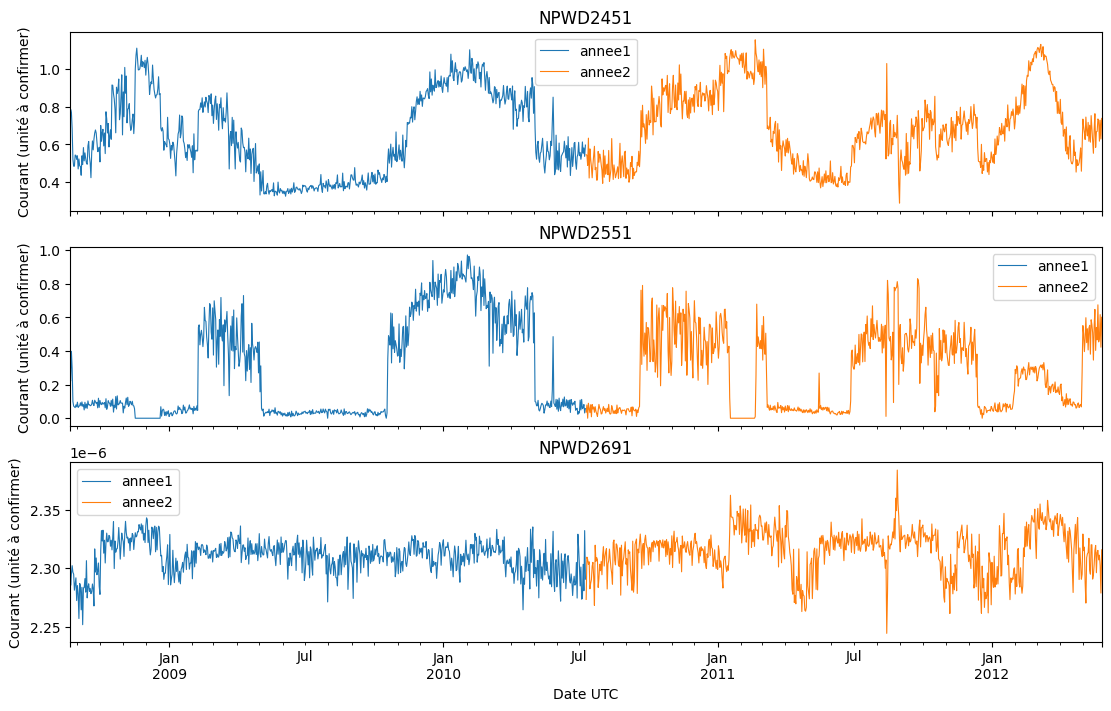

In [9]:
display(stats_circuits['annee1'].sort_values('std', ascending=False))
ordre = stats_circuits['annee1']['std'].sort_values(ascending=False).index
selection = [ordre[0], ordre[1], ordre[-1]]
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
for ax, circuit in zip(axes, selection):
    for periode in PERIODES:
        power_journalier[periode][circuit].plot(ax=ax, label=periode, linewidth=0.8)
    ax.set(title=circuit, ylabel='Courant (unité à confirmer)')
    ax.legend()
axes[-1].set_xlabel('Date UTC')
plt.show()

### Observer le changement entre apprentissage et validation

Une moyenne différente entre périodes peut annoncer une baseline constante moins adaptée.
Ce diagnostic ne sert pas à choisir une constante sur `annee2`.
La moyenne affichée ici porte sur les mesures brutes ; la future baseline devra être définie sur la cible horaire.

In [10]:
comparaison = pd.DataFrame({p: stats_circuits[p]['mean'] for p in PERIODES})
comparaison['difference'] = comparaison['annee2'] - comparaison['annee1']
ordre_difference = comparaison['difference'].abs().sort_values(ascending=False).index
display(comparaison.loc[ordre_difference].head(8))

,annee1,annee2,difference
NPWD2851,0.201417,0.323003,0.121587
NPWD2531,0.118973,0.010710,-0.108262
NPWD2532,1.231736,1.318994,0.087258
NPWD2451,0.644853,0.685062,0.040210
NPWD2881,0.058314,0.034630,-0.023685
NPWD2721,0.122376,0.142915,0.020540
NPWD2372,0.114662,0.133361,0.018700
NPWD2742,0.007220,0.025764,0.018545


## 5. Mettre consommation et éclipses côte à côte

On regarde `annee1` : le circuit le plus variable et la durée d'éclipse fournie dans `ltdata`.
Les deux graphiques partagent les dates, avec des unités différentes.
Une coïncidence visuelle propose une hypothèse ; elle ne prouve ni causalité, ni identité d'un circuit de chauffage.
Il faudra plus tard comparer des modèles avec et sans information d'éclipse pour mesurer son apport.

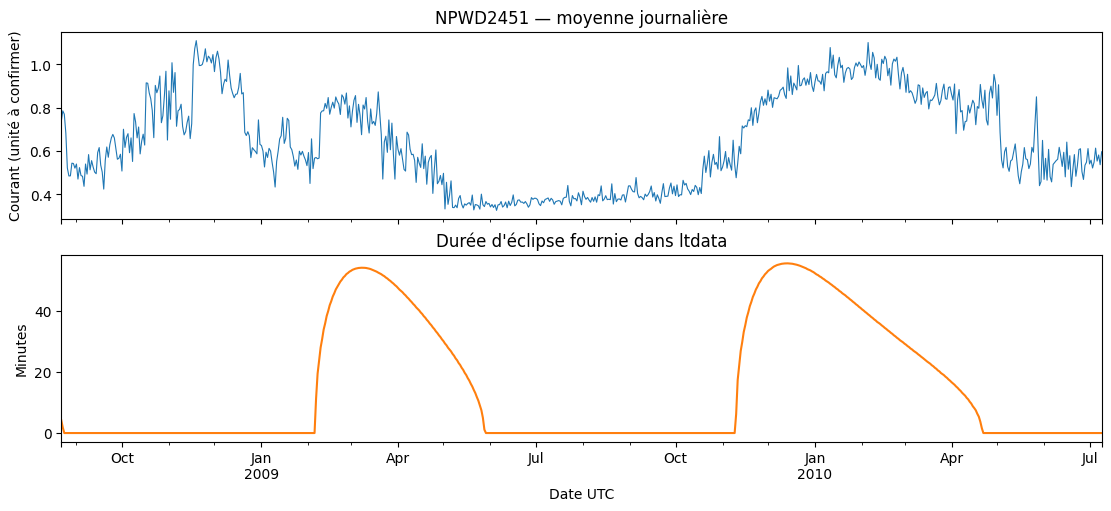

In [11]:
contexte_journalier = contextes['annee1', 'ltdata'].copy()
contexte_journalier.index = pd.to_datetime(contexte_journalier['ut_ms'], unit='ms', utc=True)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
power_journalier['annee1'][selection[0]].plot(ax=axes[0], linewidth=0.8)
axes[0].set(title=f'{selection[0]} — moyenne journalière', ylabel='Courant (unité à confirmer)')
contexte_journalier['eclipseduration_min'].plot(ax=axes[1], color='tab:orange')
axes[1].set(title="Durée d'éclipse fournie dans ltdata", ylabel='Minutes', xlabel='Date UTC')
plt.show()

## 6. Vérifier les conclusions avant de les défendre

Les assertions suivantes contrôlent les conditions attendues du kit local.
Une assertion échouée demande une enquête ; elle ne doit pas être supprimée pour masquer un problème.
Les compteurs d'heures vides restent des résultats, pas des valeurs à corriger automatiquement.

In [12]:
assert len(bilan_contexte) == 10 and len(bilan_power) == 2
assert bilan_contexte['temps_trie'].all() and bilan_power['temps_trie'].all()
assert bilan_contexte[['cellules_NaN', 'cellules_infinies', 'doublons_ligne']].eq(0).all().all()
assert bilan_power[['cellules_NaN', 'cellules_infinies', 'doublons_ligne', 'instants_repetes']].eq(0).all().all()
assert bilan_power.loc['annee1', 'fin_UTC'] < bilan_power.loc['annee2', 'debut_UTC']
assert bilan_power['circuits'].eq(33).all()
assert pd.DataFrame(bilans_planning)['durees_non_positives'].eq(0).all()

for periode in PERIODES:
    commandes = bilan_contexte.query("periode == @periode and fichier == 'dmop'").iloc[0]
    retard_jours = (bilan_power.loc[periode, 'fin_UTC'] - commandes['fin_UTC']).total_seconds() / 86400
    print(f"{periode} : {bilan_power.loc[periode, 'lignes']:,} mesures ; "
          f"{bilan_power.loc[periode, 'heures_vides']} heures vides ; "
          f"dernière commande {retard_jours:.2f} jours avant la dernière mesure.")
print('Contrôles terminés : schémas, valeurs, chronologie, comptages et intervalles vérifiés.')

annee1 : 1,830,121 mesures ; 32 heures vides ; dernière commande 0.00 jours avant la dernière mesure.
annee2 : 1,768,248 mesures ; 246 heures vides ; dernière commande 12.56 jours avant la dernière mesure.
Contrôles terminés : schémas, valeurs, chronologie, comptages et intervalles vérifiés.


## Ce que tu peux défendre à ce stade

- Les deux périodes sont consécutives ; les noms `annee1` et `annee2` ne signifient pas exactement un an chacune.
- Les 33 circuits n'ont ni la même amplitude, ni la même variabilité. La RMSE commune sera sensible aux grands écarts.
- L'absence de `NaN` ne garantit pas la continuité temporelle : le diagnostic horaire révèle les trous.
- Plusieurs événements peuvent arriver au même instant ; les supprimer à partir du seul temps ferait perdre de l'information.
- Certains intervalles du planning se chevauchent. Une somme naïve des durées pourrait dépasser une heure.
- La dernière commande d'`annee2` précède la fin de la consommation. On ne peut pas conclure que le satellite était inactif ensuite.

**Lien avec les scripts existants, lus mais non exécutés ici :** `make_validation.py` conserve les heures ayant des mesures
dans la vérité, mais demande une prédiction sur toute la grille future. `evaluate.py` note les cellules dont la vérité existe.
Il faudra donc produire des prédictions même pour les heures sans vérité, sans inventer de cible d'entraînement.

**Prochaine étape proposée :** définir les règles d'alignement horaire, vérifier les chevauchements et les trous, puis écrire `dio/prepare.py`.
Ensuite seulement : baseline constante (`baselines/`), `predict.py`, évaluation officielle. Ces fichiers sont écrits après ce notebook.

**À confirmer :** provenance et conformité des données locales au kit autorisé, unité des courants, signification des codes et des angles.
Le sujet interdit les données extérieures ; ce notebook ne télécharge rien.

**Pour vérifier ta compréhension :** pourquoi une heure sans mesure ne vaut-elle pas zéro ?
Pourquoi ne peut-on pas utiliser les courants réels d'`annee2` après les 7 premiers jours comme entrées du modèle ?